Feed screen 1, stale runs (3+ mornings with a move under 0.02bp):
  1Y: 2024-07-16 to 2024-07-25 (8 mornings)
Feed screen 2, kink jumps over 8bp: 6
  2024-11-20 3Y -10.4bp
  2024-11-20 5Y +28.5bp
  2024-11-20 7Y -16.0bp
  2024-11-21 3Y +10.1bp
  2024-11-21 5Y -29.9bp
  2024-11-21 7Y +16.1bp
Walk screen, late bookings:
ticket     traded     booked    bond  face  lag
  T023 2024-09-09 2024-09-12 GOV_29B     8    3

Each incident in the operations log against each screen (first morning it fired, mornings of delay):
  id  kind        mornings      PNL_FIXED   PNL_SCALED        STALE         KINK         LATE
  I1  WRONG_SIDE         4       04-11 +0     04-11 +0            -            -            -
  I2  NOTIONAL          10       06-13 +0     06-13 +0            -            -            -
  I3  LATE               3              -            -            -            -     09-12 +2
  I4  MISSED            54       10-16 +0     10-16 +0            -    11-20 +25            -
  I5  STALE 

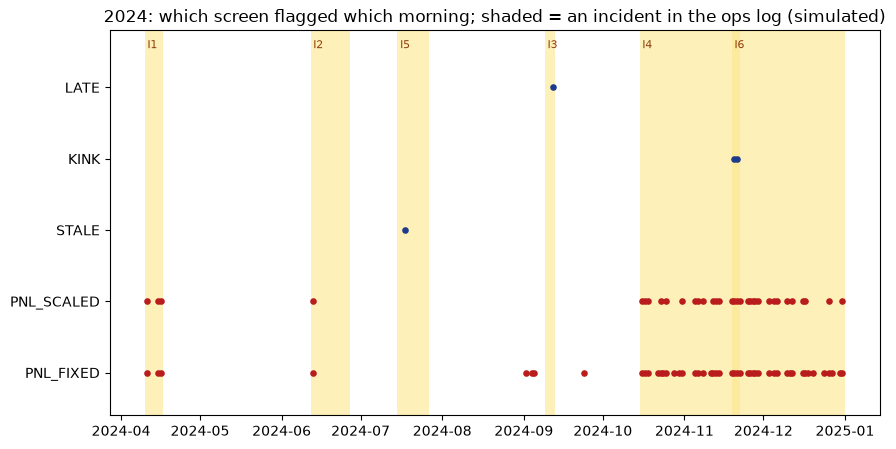

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# == Setup (done for you) ==
df = pd.read_csv(
    r'C:\Users\franklinpeng\Desktop\RDA Risk test\DataSource\rates_desk_feed.csv',
    parse_dates=['date'],
    index_col='date'
)
DATES = df.index                                   # business days 2020-12-31 .. 2024-12-31
LAB = [c[2:] for c in df.columns if c.startswith('Z_')]          # '3M', '6M', ..., '30Y'
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])       # years of the Z_ columns: the curve's VERTICES
Z = df[['Z_' + x for x in LAB]].to_numpy()         # the curve FEED as received: zero yields, %, continuously compounded
PNL = df['PNL_REPORTED'].to_numpy()                # the P&L system's daily desk P&L, USD (NaN before 2023-01-03)
REP = np.where(DATES >= '2023-01-03')[0]           # report mornings: every day with a reported P&L
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)


def cash_flows(bond):
    """Done for you: the bond's payment dates after the data starts (every 6 months back from maturity, unadjusted)
    and its payments per 100 face: coupon / 2 on each date, + 100 at maturity."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """Done for you: weights W (shape tau.shape + (11,)) with W @ curve = the zero rate at each tau, linear between
    vertices and flat beyond the first and last. Each row has at most two non-zero weights, summing to 1."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2


def positions_history(blotter=BLOTTER):
    """Done for you (Task 1's book_on, for every day at once): the position in each bond (days x bonds, USD m
    face) at each close. Each blotter row changes its ticket's face from that row's booked date onwards."""
    b = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face'])
    step = b['face'] - b.groupby('ticket')['face'].shift(1).fillna(0)
    Q = np.zeros((len(DATES), len(IDS)))
    for r, bond, s in zip(DATES.searchsorted(pd.to_datetime(b['booked'])), b['bond'], step):
        Q[r:, IDS.index(bond)] += s
    return Q


def history(curves):
    """Done for you (Task 1's price_and_ladder, for every day and bond at once). Per 100 face, rows = days, columns =
    bonds: V = value off curve t on day t; VA = value off curve t-1 on day t (the bond one day OLDER, on YESTERDAY's
    curve); K, KA = the key-rate ladders of the same two (days x bonds x 11); CASH = what the bond paid in (t-1, t]."""
    prev = np.vstack([curves[:1], curves[:-1]])
    out = {k: [] for k in ('V', 'VA', 'K', 'KA', 'CASH')}
    for bond in IDS:
        dates, cf = cash_flows(bond)
        tau = (dates.values[None, :] - DATES.values[:, None]) / np.timedelta64(1, 'D') / 365.0
        live = tau > 0
        W = interp_weights(np.where(live, tau, 1.0))
        for name, C in (('', curves), ('A', prev)):
            dfac = np.where(live, np.exp(-np.einsum('nmk,nk->nm', W, C) / 100 * tau), 0.0)
            out['V' + name].append(dfac @ cf)
            out['K' + name].append(np.einsum('nm,nmk->nk', dfac * cf * tau, W) * 1e-4)
        paid = (dates.values[None, :] > DATES.values[:-1, None]) & (dates.values[None, :] <= DATES.values[1:, None])
        out['CASH'].append(np.concatenate([[0.0], paid.astype(float) @ cf]))
    return {k: np.stack(v, axis=1) for k, v in out.items()}


UNIT = 1e4    # USD per (USD m face x price per 100): a position's USD value = face x UNIT x value per 100

INCIDENT_LOG = [   # the operations review of 2024, written after year-end: the GRADING KEY, never an input to a screen
    # first / last = the report mornings the incident could show on (a booking error held overnight from day s shows
    # in the P&L of morning s + 1 onwards; a feed fault shows on its own mornings)
    {'id': 'I1', 'kind': 'WRONG_SIDE', 'first': '2024-04-11', 'last': '2024-04-16', 'bond': 'GOV_34', 'error_m': +100,
     'what': 'T019 was a SALE of 50m GOV_34, booked as a purchase; amended 2024-04-16'},
    {'id': 'I2', 'kind': 'NOTIONAL', 'first': '2024-06-13', 'last': '2024-06-26', 'bond': 'GOV_27B', 'error_m': +36,
     'what': 'T021 bought 4m GOV_27B, booked as 40m; amended 2024-06-26'},
    {'id': 'I3', 'kind': 'LATE', 'first': '2024-09-10', 'last': '2024-09-12', 'bond': 'GOV_29B', 'error_m': -8,
     'what': 'T023 bought 8m GOV_29B on 2024-09-09, booked 2024-09-12'},
    {'id': 'I4', 'kind': 'MISSED', 'first': '2024-10-16', 'last': '2024-12-31', 'bond': 'GOV_33', 'error_m': -60,
     'what': 'T024 bought back 60m GOV_33 (closing the short) on 2024-10-15; never reached the risk system'},
    {'id': 'I5', 'kind': 'STALE', 'first': '2024-07-16', 'last': '2024-07-26', 'bond': None, 'error_m': 0,
     'what': 'Z_1Y frozen at its 2024-07-15 value on 8 mornings, 2024-07-16 to 2024-07-25'},
    {'id': 'I6', 'kind': 'BAD_PRINT', 'first': '2024-11-20', 'last': '2024-11-21', 'bond': None, 'error_m': 0,
     'what': 'Z_5Y printed 31bp too high on 2024-11-20 only'},
]   # error_m = booked minus true position, USD m face, while the incident lasts
MISSING_TICKETS = [('T024', '2024-10-15', '2024-10-15', 'GOV_33', 60)]
CORRECTIONS = {   # the vendor's corrected values for the faulty feed points: (date, column): zero yield %
    ('2024-07-16', 'Z_1Y'): 4.7904, ('2024-07-17', 'Z_1Y'): 4.7981, ('2024-07-18', 'Z_1Y'): 4.7587,
    ('2024-07-19', 'Z_1Y'): 4.7402, ('2024-07-22', 'Z_1Y'): 4.6895, ('2024-07-23', 'Z_1Y'): 4.6907,
    ('2024-07-24', 'Z_1Y'): 4.6368, ('2024-07-25', 'Z_1Y'): 4.7069, ('2024-11-20', 'Z_5Y'): 4.4186,
}


def corrected_blotter():
    """Done for you: every ticket as finally amended, effective from its TRADED date, plus the tickets the risk
    system never received. This is the true book."""
    last = {}
    for row in BLOTTER + MISSING_TICKETS:
        last[row[0]] = row
    return [(t, traded, traded, bond, face) for (t, booked, traded, bond, face) in last.values()]


def corrected_feed():
    """Done for you: the curve feed with the vendor's corrections applied."""
    Zc = Z.copy()
    for (day, col), v in CORRECTIONS.items():
        Zc[DATES.get_loc(pd.Timestamp(day)), LAB.index(col[2:])] = v
    return Zc


def stale_runs(curves, tol=0.0002, min_len=3):
    """TODO: Feed screen 1: runs of at least `min_len` consecutive mornings on which a vertex moved by less than `tol`
    (in %, so 0.0002 = 0.02bp). Returns a list of (vertex label, first morning, last morning, length).
    Walk down each column of np.diff(curves, axis=0) counting the current run of tiny moves."""
    runs = []
    tiny = np.abs(np.diff(curves, axis=0)) < tol

    for j, label in enumerate(LAB):
        start = None

        for t in range(1, len(curves)):
            if tiny[t - 1, j]:
                if start is None:
                    start = t
            elif start is not None:
                length = t - start
                if length >= min_len:
                    runs.append((
                        label, DATES[start], DATES[t - 1], length
                    ))
                start = None

        if start is not None:
            length = len(curves) - start
            if length >= min_len:
                runs.append((
                    label, DATES[start], DATES[-1], length
                ))

    return runs



def kink_jumps(curves, limit_bp=8.0):
    """TODO: Feed screen 2: days on which an inner vertex jumped AWAY from its neighbours. kink = the vertex minus the
    straight line between its two neighbours (weights by maturity); flag every (day, vertex, change in bp) where
    the kink moved by more than `limit_bp` in one day. A true curve move shifts neighbours together; a bad print
    moves one point."""
    jumps = []

    for j in range(1, len(TEN) - 1):
        weight = (
            (TEN[j] - TEN[j - 1])
            / (TEN[j + 1] - TEN[j - 1])
        )

        interpolated = (
            curves[:, j - 1] * (1 - weight)
            + curves[:, j + 1] * weight
        )

        kink = curves[:, j] - interpolated
        changes_bp = np.diff(kink) * 100

        for t in np.where(np.abs(changes_bp) > limit_bp)[0]:
            jumps.append((
                DATES[t + 1],
                LAB[j],
                float(changes_bp[t])
            ))

    return sorted(jumps, key=lambda x: x[0])


def late_bookings(blotter=BLOTTER):
    """TODO: Walk screen: tickets whose FIRST row was booked after the trade date (the trade was live before the risk
    system knew). Returns a DataFrame of ticket, traded, booked, bond, face, lag (business days)."""
    b = pd.DataFrame(
        blotter,
        columns=['ticket', 'booked', 'traded', 'bond', 'face']
    )

    b = b.drop_duplicates('ticket', keep='first').copy()

    b['booked'] = pd.to_datetime(b['booked'])
    b['traded'] = pd.to_datetime(b['traded'])

    late = b[b['booked'] > b['traded']].copy()

    late['lag'] = np.busday_count(
        late['traded'].values.astype('datetime64[D]'),
        late['booked'].values.astype('datetime64[D]')
    )

    return late[
        ['ticket', 'traded', 'booked', 'bond', 'face', 'lag']
    ].reset_index(drop=True)



def implied_dv01(U, moves, idx):
    """TODO: The DV01 the OTHER system holds and we do not, read off the unexplained P&L of mornings `idx`: regress U on
    the day's parallel move m (average of the 11 vertex moves, bp) through zero: -sum(U m) / sum(m^2)."""
    m = moves[idx].mean(axis=1)

    numerator = np.sum(U[idx] * m)
    denominator = np.sum(m ** 2)

    if denominator == 0:
        return np.nan

    return -float(numerator / denominator)


# ---------------------------------------------------------------------------
H = history(Z)
Q = positions_history() * UNIT
moves = np.vstack([np.zeros((1, 11)), np.diff(Z, axis=0) * 100])
checks = [('stale_runs', lambda: stale_runs(Z[:40])), ('kink_jumps', lambda: kink_jumps(Z[:40])),
          ('late_bookings', lambda: late_bookings()), ('implied_dv01', lambda: implied_dv01(np.ones(10), moves, np.arange(1, 6)))]
todo = next((name for name, f in checks if f() is None), None)
if todo:
    print(f"Fill in the TODOs above, then run again. Next: {todo}()")
else:
    Qp = np.vstack([Q[:1], Q[:-1]])
    L_prev = np.einsum('nb,nbk->nk', Qp, np.vstack([H['K'][:1], H['K'][:-1]]))
    c = (Qp * (H['VA'] + H['CASH'] - np.vstack([H['V'][:1], H['V'][:-1]]))).sum(1)
    U = PNL - c + (L_prev * moves).sum(1)                       # Task 3's unexplained P&L
    g2 = np.sqrt((L_prev ** 2).sum(1))
    y23, y24 = REP[DATES[REP].year == 2023], REP[DATES[REP].year == 2024]
    s = float(np.std(U[y23]) / np.sqrt(2 * np.mean(g2[y23] ** 2)))
    z = U / (np.sqrt(2) * s * g2)                                 # Task 3's z, noise model fitted on 2023
    days24 = DATES[y24]
    flag = pd.DataFrame(False, index=days24, columns=['PNL_FIXED', 'PNL_SCALED', 'STALE', 'KINK', 'LATE'])
    flag['PNL_FIXED'] = np.abs(U[y24]) > 3.5 * np.std(U[y23])
    flag['PNL_SCALED'] = np.abs(z[y24]) > 3.5
    st, kj, lb = stale_runs(Z), kink_jumps(Z), late_bookings()
    print("Feed screen 1, stale runs (3+ mornings with a move under 0.02bp):")
    for lbl, a, b, n_ in st:
        print(f"  {lbl}: {a.date()} to {b.date()} ({n_} mornings)")
        flag.loc[days24[days24.searchsorted(a) + 2] if a.year == 2024 else days24[0], 'STALE'] = True  # flags on its 3rd morning
    print(f"Feed screen 2, kink jumps over 8bp: {len(kj)}")
    for day, lbl, ch in kj:
        print(f"  {day.date()} {lbl} {ch:+.1f}bp")
        if day in flag.index:
            flag.loc[day, 'KINK'] = True
    print("Walk screen, late bookings:")
    print(lb.to_string(index=False))
    for _, r in lb.iterrows():
        if pd.Timestamp(r.booked) in flag.index:
            flag.loc[pd.Timestamp(r.booked), 'LATE'] = True

    print("\nEach incident in the operations log against each screen (first morning it fired, mornings of delay):")
    live = pd.Series(False, index=days24)
    print(f"  {'id':<4}{'kind':<11}{'mornings':>9}  " + ''.join(f"{k:>13}" for k in flag.columns))
    for inc in INCIDENT_LOG:
        win = (days24 >= inc['first']) & (days24 <= inc['last'])
        live |= win
        cells = []
        for k in flag.columns:
            hit = np.where(flag[k].to_numpy() & win)[0]
            w0 = np.where(win)[0][0]
            cells.append(f"{str(days24[hit[0]].date())[5:]} +{hit[0] - w0}" if len(hit) else '-')
        print(f"  {inc['id']:<4}{inc['kind']:<11}{win.sum():>9}  " + ''.join(f"{x:>13}" for x in cells))
    for k in flag.columns:
        print(f"  {k:<11} red on {flag[k].sum():>3} mornings of 2024, {(flag[k] & ~live).sum():>3} of them with no incident live")

    print("\nImplied DV01 of the gap (the DV01 the P&L system holds and we do not) vs the log's error:")
    for inc in INCIDENT_LOG:
        if not inc['bond']:
            continue
        idx = y24[(days24 >= inc['first']) & (days24 <= inc['last'])]
        b = IDS.index(inc['bond'])
        err = -inc['error_m'] * UNIT * H['K'][idx - 1, b].sum(1).mean()      # true minus booked, USD per bp
        print(f"  {inc['id']} {inc['kind']:<11} {len(idx):>3} mornings: implied {implied_dv01(U, moves, idx):>+10,.0f}"
              f"   log ({inc['error_m']:+d}m {inc['bond']}) {err:>+10,.0f}")

    def var_today(curves, blotter):
        h = history(curves)
        lad = np.einsum('b,bk->k', positions_history(blotter)[-1] * UNIT, h['K'][-1])
        mv = np.diff(curves[-VAR_DAYS - 1:], axis=0) * 100
        return float(-np.sort(-mv @ lad)[VAR_K - 1])
    Zc = corrected_feed()
    v0, v1, v2 = var_today(Z, BLOTTER), var_today(Zc, BLOTTER), var_today(Zc, corrected_blotter())
    print(f"\nVaR at the close of {DATES[-1].date()}: as received USD {v0:,.0f}; feed corrected USD {v1:,.0f}; "
          f"feed and book corrected USD {v2:,.0f} (the reported VaR was {100 * (1 - v0 / v2):.1f}% too low)")
    lad = np.einsum('b,bk->k', Q[-1], H['K'][-1])
    sc = pd.Series(-moves[-VAR_DAYS:] @ lad, index=DATES[-VAR_DAYS:]).sort_values()
    p = pd.Timestamp('2024-11-20')
    print(f"  the bad print's scenario ({p.date()}) is number {sc.index.get_loc(p) + 1} of {VAR_DAYS} in today's "
          f"window, P&L USD {sc[p]:+,.0f}; the 5th and 6th worst are USD {sc.iloc[4]:+,.0f} and {sc.iloc[5]:+,.0f}")

    fig, ax = plt.subplots(figsize=(9, 4.6))
    y = {k: i for i, k in enumerate(flag.columns)}
    for inc in INCIDENT_LOG:
        ax.axvspan(pd.Timestamp(inc['first']) - pd.Timedelta(days=1), pd.Timestamp(inc['last']) + pd.Timedelta(days=1),
                   color='#fde68a', alpha=0.6, lw=0)
        ax.text(pd.Timestamp(inc['first']), len(y) - 0.45, inc['id'], fontsize=8, color='#92400e')
    for k, i in y.items():
        d = flag.index[flag[k]]
        ax.scatter(d, np.full(len(d), i), s=14, color='#b91c1c' if k.startswith('PNL') else '#1e3a8a')
    ax.set_yticks(list(y.values()))
    ax.set_yticklabels(list(y.keys()))
    ax.set_ylim(-0.6, len(y) - 0.2)
    ax.set_title('2024: which screen flagged which morning; shaded = an incident in the ops log (simulated)')
    plt.tight_layout()
    plt.show()
